# 01 — Datasets: from raw text to index tensors

**Chapter 2 · From bigram to mini-GPT** · suggested time: 20 min · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_2/01_datasets.ipynb)

![Chapter roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/00_roadmap.png)

In chapter 1, we worked on **names**. We now move on to **real texts**: a language model learns the way *one* text is written. Change the text, and you change what the model will imitate.

**By the end of this notebook you will be able to:**
1. load and compare three corpora (Shakespeare, Kaamelott, Plato);
2. explain what a character **vocabulary** and a **tokenizer** are;
3. turn a text into a `torch.long` tensor of indices;
4. split **training** and **validation** data, and say why corpus size matters.

> **Key idea:** a neural network does not read letters. It only handles numbers. So the whole pipeline starts with a lookup table *character ↔ integer*.

In [1]:
# On Google Colab: fetch the course repository (corpora + shared modules such as minigpt.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_2

In [2]:
# Setup: imports and the chapter's shared module
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # the file minigpt.py, next to this notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0+cu132 | device: cuda


## 1. Three corpora, three "styles" to imitate

| Corpus | File | Content |
|---|---|---|
| **Shakespeare** | `shakespeare.txt` | *Tiny Shakespeare*: excerpts from plays, ≈ 1 M characters. This is the corpus from Karpathy's video. |
| **Kaamelott** | `kaamelott.txt` | The 455 episodes of the French TV series (Kaggle dataset [*Kaamelott TV show transcripts*](https://www.kaggle.com/datasets/jeanmidev/kaamelott-tv-show-transcripts-fr)), one line of dialogue per line in the format `SPEAKER: line`, ≈ 2.4 M characters. |
| **Plato** | `plato_train.txt` | Plato's dialogues in Victor Cousin's French translation (19th century), ≈ 4 M characters. |

The texts are used **as is**. Only Kaamelott was formatted once and for all from the dataset's CSV file (script `preparer_kaamelott.py`, next to the corpora): one line of dialogue per line, an empty line between two episodes. Plato's `=== PLA_... ===` lines (dialogue titles) are part of the text the model will learn.

The function `minigpt.load_text(name)` simply looks for the file next to the notebook, then in the repository's `corpus/` folder: it is an `open(...).read()`.

In [3]:
texts = {name: minigpt.load_text(name) for name in ["shakespeare", "kaamelott", "plato"]}

for name, text in texts.items():
    print(f"=== {name}: {len(text):,} characters ===")
    print(text[:300])
    print()

=== shakespeare: 1,115,394 characters ===
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us

=== kaamelott: 2,429,148 characters ===
KARADOC: Bon, je vais essayer de trouver un petit lièvre pour ce soir parce qu’il commence à faire faim !
BOHORT: Je me demande comment vous faîtes, moi je serais incapable de trouver de quoi manger dans la forêt.
KARADOC: Pour attraper des bêtes, il faut imiter les femelles. Là, pour le coup, hop !

=== plato: 3,892,898 characters ===
=== PLA_Apologie_de_Socrate ===

MÉLITUS:
Non, sans doute.

SOCRATE:
Eh bien donc, dis à nos juges qui est-ce qui est capable de rendre les jeunes gens meilleurs ; car il ne faut pas douter que tu ne le saches, puisque cela t'occupe si fort. En effet, puisque tu as découvert ce

### Reading the previews

- **Line breaks**, **spaces** and **punctuation** are characters like any other. So the model will also learn the *layout*: speaker names, colons, line breaks between lines of dialogue.
- Shakespeare is in English (no accents), Kaamelott and Plato are in French (with `é`, `è`, `ç`, `’`…).

**Question:** which of the three corpora do you think will have the largest character vocabulary? Which one will be the hardest to learn?

In [4]:
# Compare the three corpora in numbers
print(f"{'corpus':12s} {'characters':>12s} {'vocabulary':>12s} {'lines':>8s} {'distinct words':>15s}")
for name, text in texts.items():
    vocab = sorted(set(text))
    print(f"{name:12s} {len(text):12,} {len(vocab):12d} {text.count(chr(10)):8,} {len(set(text.split())):15,}")

corpus         characters   vocabulary    lines  distinct words
shakespeare     1,115,394           65   40,000          25,670
kaamelott       2,429,148          116   32,948          35,483


plato           3,892,898          111   33,627          37,630


**What to notice:**

- **Kaamelott is more than twice the size of Shakespeare** (≈ 2.4 M characters versus 1.1 M): enough to learn the style of the lines, the speakers' names and their verbal tics.
- **Plato is the largest**: it contains more examples, but also a larger vocabulary (accents, typographic quotes…).
- The number of **distinct words** is huge compared with the number of **distinct characters**. This is why we work at the character level: a vocabulary of a few dozen symbols is enough to write any word.

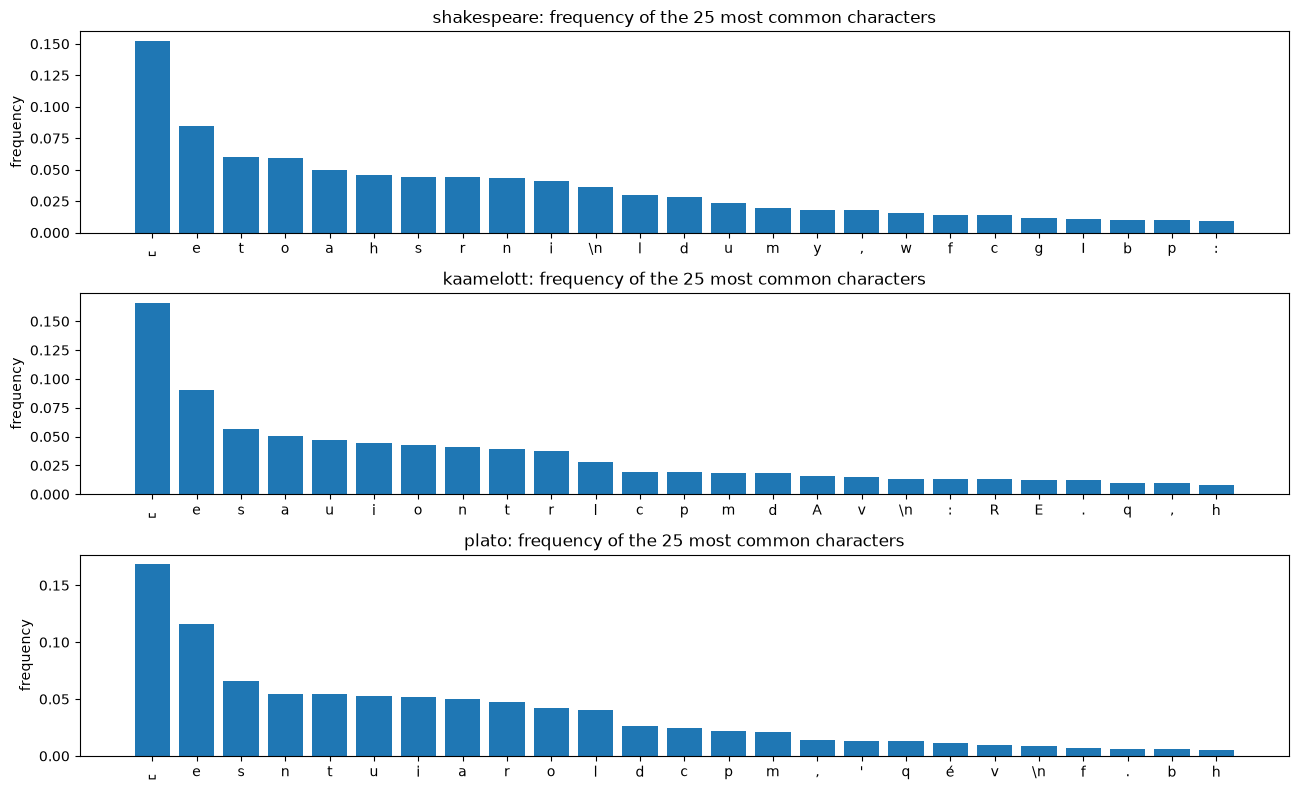

In [5]:
# Which characters are the most frequent? (top 25)
from collections import Counter

fig, axes = plt.subplots(3, 1, figsize=(13, 8))
for ax, (name, text) in zip(axes, texts.items()):
    top = Counter(text).most_common(25)
    labels = [repr(c)[1:-1] if c not in " \n" else {" ": "␣", "\n": "\\n"}[c] for c, _ in top]
    ax.bar(labels, [n / len(text) for _, n in top])
    ax.set_title(f"{name}: frequency of the 25 most common characters")
    ax.set_ylabel("frequency")
plt.tight_layout(); plt.show()

The **space** dominates everywhere, followed by the vowels. A model that learned nothing but these frequencies would already beat chance: this is exactly what the bigram, then the Transformer, will go beyond.

---
## 2. The tokenizer: one character = one integer

We adopt the **simplest possible tokenizer**:

- `chars`: the sorted list of all characters present in the text; this is the **vocabulary** (size `V`);
- `stoi` (*string to integer*): character → index;
- `itos` (*integer to string*): index → character;
- `encode` / `decode`: apply these tables to a whole string.

This code is identical to the one in `minigpt.py` (class `CharTokenizer`), which the next notebooks will import.

In [6]:
class CharTokenizer:
    """The simplest tokenizer: one character = one integer."""

    def __init__(self, text):
        self.chars = sorted(set(text))
        self.vocab_size = len(self.chars)
        self.stoi = {ch: i for i, ch in enumerate(self.chars)}
        self.itos = {i: ch for i, ch in enumerate(self.chars)}

    def encode(self, s):
        return [self.stoi[c] for c in s]

    def decode(self, ids):
        return "".join(self.itos[int(i)] for i in ids)


tok = CharTokenizer(texts["shakespeare"])
print("Vocabulary:", repr("".join(tok.chars)))
print("V =", tok.vocab_size)
print()
print("encode('Hi there') =", tok.encode("Hi there"))
print("decode(...)        =", repr(tok.decode(tok.encode("Hi there"))))

Vocabulary: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
V = 65

encode('Hi there') = [20, 47, 1, 58, 46, 43, 56, 43]
decode(...)        = 'Hi there'


**An index is a label, not a quantity.** The fact that `e` has number 43 and `a` number 39 does not mean that `e` is "bigger" than `a`, nor that they are similar. This is why the model will never use the index directly in a computation: it will use it to **read a row in a table** (an *embedding*, notebook 02).

### Each corpus has its own vocabulary

The tokenizer is built **from the text**. A character that is absent from the training corpus has no index: the model can neither read it nor write it.

In [7]:
tokenizers = {name: CharTokenizer(t) for name, t in texts.items()}
for name, t in tokenizers.items():
    print(f"{name:12s} V = {t.vocab_size:3d} | {''.join(t.chars)[:90]!r}")

sentence = "Arthur, c'est pas faux !"
for name, t in tokenizers.items():
    try:
        t.encode(sentence)
        print(f"{name:12s} can encode {sentence!r}")
    except KeyError as e:
        print(f"{name:12s} does not know the character {e}")

shakespeare  V =  65 | "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
kaamelott    V = 116 | '\n !"%&\'()+,-./0123456789:;<=>?ABCDEFGHIJKLMNOPQRSTUVWXYZ[]^abcdefghijklmnopqrstuvwxyz{«»ÀÇ'
plato        V = 111 | '\n !"&\'(),-.0123456789:;<=>?ABCDEFGHIJLMNOPQRSTUVWXYZ[\\]^_abcdefghijklmnopqrstuvwxyz|´·ÀÆÇÈ'
shakespeare  can encode "Arthur, c'est pas faux !"
kaamelott    can encode "Arthur, c'est pas faux !"
plato        can encode "Arthur, c'est pas faux !"


(*"C'est pas faux"*, "that's not wrong", is a famous Kaamelott catchphrase.)

Notice the trap: Kaamelott contains **two apostrophes**, the straight `'` and the typographic `’`, depending on the episode (about 16,000 and 19,000 occurrences). For the model, they are two **completely unrelated** symbols: it will have to learn "c'est", "l'épée", "j'ai"… twice. A human sees the same sign, the tokenizer does not.

> **Going further:** "industrial" GPTs do not use characters but **subwords** (BPE: `"Arthur"` → `["Ar", "thur"]`). The vocabulary grows to ~50,000 – 200,000 tokens and each token carries more meaning. **Everything else in the chapter still holds**: only the tokenizer changes. See Karpathy's video [*Let's build the GPT Tokenizer*](https://www.youtube.com/watch?v=zduSFxRajkE).

---
## 3. The whole corpus becomes a tensor

Once `encode` is defined, the whole corpus fits in **a single long vector of integers**. The `torch.long` type is mandatory: these integers will be used as indices for `nn.Embedding`.

In [8]:
CORPUS = "shakespeare"     # try "kaamelott" or "plato"
text = texts[CORPUS]
tok = tokenizers[CORPUS]

data = torch.tensor(tok.encode(text), dtype=torch.long)
print("data:", data.shape, data.dtype)
print("First 60 indices:", data[:60].tolist())
print("Decoded         :", repr(tok.decode(data[:60])))

data: torch.Size([1115394]) torch.int64
First 60 indices: [18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52, 10, 0, 14, 43, 44, 53, 56, 43, 1, 61, 43, 1, 54, 56, 53, 41, 43, 43, 42, 1, 39, 52, 63, 1, 44, 59, 56, 58, 46, 43, 56, 6, 1, 46, 43, 39, 56, 1, 51, 43, 1, 57, 54, 43, 39, 49, 8]
Decoded         : 'First Citizen:\nBefore we proceed any further, hear me speak.'


At this point, `data` contains **no knowledge**: just numbers. Learned vector representations will appear with embeddings.

---
## 4. Splitting training and validation

We keep the **first 90%** of the characters for training and the **last 10%** for validation.

- **Training loss**: measured on the text used to adjust the weights.
- **Validation loss**: measured on a text **never used** for the updates. This is the one that tells whether the model **generalizes**.

If the training loss goes down while the validation loss goes back up, the model is **reciting** instead of learning: this is **overfitting**.

**Why split in order rather than at random?** If we drew characters at random, each validation character would be surrounded by its neighbors… which are in the training set. Validation would become too easy. Cutting a single block gives an honest evaluation on a genuinely new passage.

In [9]:
for name in texts:
    _, t, train_data, val_data = minigpt.prepare_data(name)
    print(f"{name:12s} train = {len(train_data):9,} characters | val = {len(val_data):7,} characters | V = {t.vocab_size}")

shakespeare  train = 1,003,854 characters | val = 111,540 characters | V = 65


kaamelott    train = 2,186,233 characters | val = 242,915 characters | V = 116


plato        train = 3,503,608 characters | val = 389,290 characters | V = 111


Since the split is done in order, Kaamelott's validation set corresponds to the **last episodes** of the series, and Plato's to the last dialogues in the file: the model will be evaluated on scenes it has never seen.

---
## 5. A first baseline: the "I know nothing" model

A model that gives the same probability `1/V` to every character gets a loss (negative log-likelihood, chapter 1) of

$$\mathcal{L}_{\text{uniform}} = -\log\frac{1}{V} = \log V.$$

This is the **starting line**: any model that has learned something must do better.

In [10]:
for name, t in tokenizers.items():
    print(f"{name:12s} V = {t.vocab_size:3d}  ->  uniform loss = log(V) = {math.log(t.vocab_size):.3f}")

shakespeare  V =  65  ->  uniform loss = log(V) = 4.174
kaamelott    V = 116  ->  uniform loss = log(V) = 4.754
plato        V = 111  ->  uniform loss = log(V) = 4.710


## Summary

- A corpus = one long string of characters, **spaces and line breaks included**.
- The **vocabulary** is the set of distinct characters; `stoi`/`itos` go back and forth between character ↔ integer.
- The corpus becomes a `torch.long` tensor; we split it **in order** into train (90%) / val (10%).
- The baseline loss of a model that knows nothing is `log(V)`.
- These functions live in `minigpt.py`: `load_text`, `CharTokenizer`, `prepare_data`.

**Check your understanding**
1. Why can't a model trained on Shakespeare generate the character `é`?
2. Why must a character's index not be used as a numerical quantity?
3. Why are Kaamelott's two apostrophes (`'` and `’`) a problem for a character tokenizer?

**Next → 02:** we take the bigram from chapter 1 again, this time written "the PyTorch way" with `nn.Module`, and we train it on this text.

### References
- A. Karpathy, [*char-rnn*](https://github.com/karpathy/char-rnn) — origin of the *Tiny Shakespeare* corpus.
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) (2023) and its code [ng-video-lecture](https://github.com/karpathy/ng-video-lecture).
- A. Karpathy, [*Let's build the GPT Tokenizer*](https://www.youtube.com/watch?v=zduSFxRajkE) (2024) — subword tokenization (BPE).
- Plato, *Œuvres*, translated by Victor Cousin, on [Wikisource](https://fr.wikisource.org/wiki/Auteur:Platon) (French).